# А/B-тест

Были сделаны некоторые новые алгоритмы рекомендаций новостей в ленте.  Ожидается, что новые алгоритмы сделают пользователей счастливее (то есть удлинится LTV, повысятся денежные конверсии и т.д.), а продукт удобнее/приятнее в использовании. Требуется проверить эту гипотезу.  

Показателем, увеличение которого будет говорить, что посты действительно стали интереснее примем CTR из просмотров в лайки.

Для проверки корректности работы системы сплитования пользователей проведем А/А-тест. 

Только если группы до нашего воздействия были «одинаковыми», мы позволяем себе утверждать, что возникшее после воздействия отличие вызвано воздействием.


## А/A-тест

In [1]:
import pandas as pd
import pandahouse as ph
from scipy import stats
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (15, 8)

In [2]:
connection = {'host': 'http://clickhouse.lab.karpov.courses:8123',
'database':'simulator_20251020',
'user':'student',
'password':'dpo_python_2020'
}

Берём данные АА-теста из следующего диапазона: с '2026-08-21' по '2026-08-27'

In [3]:
query = '''
select exp_group, 
    user_id,
    sum(action = 'like') as likes,
    sum(action = 'view') as views,
    likes/views as ctr
from simulator_20260920.feed_actions
where toDate(time) >= '2026-08-21' and toDate(time) <= '2026-08-27' and (exp_group = 2 or exp_group = 3)
GROUP BY exp_group, user_id
'''

In [4]:
df = ph.read_clickhouse(query, connection=connection)

In [5]:
df.head()

,exp_group,user_id,likes,views,ctr
0,3,115383,38,248,0.153226
1,3,10326,24,132,0.181818
2,3,123580,25,122,0.204918
3,2,131473,19,98,0.193878
4,2,23985,12,44,0.272727


In [6]:
df.groupby('exp_group').count()

,user_id,likes,views,ctr
exp_group,,,,
2,8362,8362,8362,8362
3,8425,8425,8425,8425


Группы примерно одиниковые по размеру

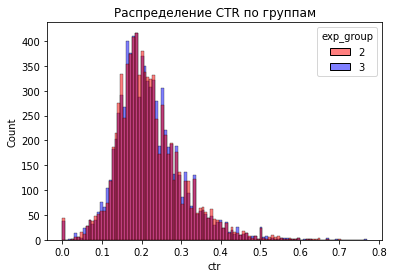

In [7]:
groups = sns.histplot(data = df, 
              x='ctr', 
              hue='exp_group', 
              palette = ['r', 'b'],
              alpha=0.5,
              kde=False)
plt.title("Распределение CTR по группам")
plt.show()

Из групп 2 и 3 берём подвыборки без возвращения размером в 500 юзеров. Повторяем 10000 раз.

In [8]:
p_values=[]

In [9]:
for _ in range(10000):
    t_stat, p_val = stats.ttest_ind(df[df.exp_group == 3].sample(500, replace=False).ctr,
                    df[df.exp_group == 2].sample(500, replace=False).ctr,
                    equal_var=False)
    p_values.append(p_val)

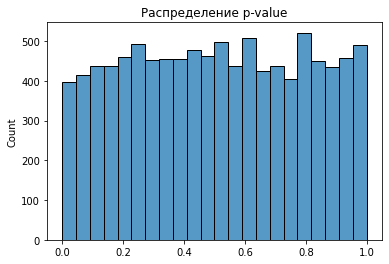

In [10]:
sns.histplot(p_values)
plt.title("Распределение p-value")
plt.show()

Доля p-value, оказавшихся ниже порога значимости в 0.05.

In [11]:
p_val_005 = len([x for x in p_values if x < 0.05]) / len(p_values)
p_val_005

0.0431

Распределение получившихся p-value является примерно равномерным
. Доля p-value ниже порога значимости составляет 0.0502
. Это примерно столько, сколько мы ожидаем. Значит, система сплитования работает корректно.

# А/B-тест

Анализ результатов эксперимента. Эксперимент проходился с 2026-08-28 по 2026-09-03 включительно. Для эксперимента были задействованы 2 и 1 группы.

В группе 2 был использован один из новых алгоритмов рекомендации постов,

группа 1 использовалась в качестве контроля.

In [12]:
query = '''
SELECT exp_group, 
    user_id,
    sum(action = 'like') as likes,
    sum(action = 'view') as views,
    likes/views as ctr
FROM simulator_20260920.feed_actions
WHERE toDate(time) >= '2026-08-28' and toDate(time) <= '2026-09-03' and (exp_group = 2 or exp_group = 1)
GROUP BY exp_group, user_id
'''

In [13]:
df = ph.read_clickhouse(query, connection=connection)

In [14]:
df.head()

,exp_group,user_id,likes,views,ctr
0,1,109963,3,15,0.200000
1,1,26117,32,141,0.226950
2,1,138232,18,73,0.246575
3,1,26295,39,141,0.276596
4,1,18392,7,32,0.218750


In [15]:
df.groupby('exp_group').count()

,user_id,likes,views,ctr
exp_group,,,,
1,10020,10020,10020,10020
2,9877,9877,9877,9877


Группы примерно одиниковые по размеру

Средние CTR по группам

In [16]:
df[df.exp_group == 1].ctr.mean()

0.216773994120072

In [17]:
df[df.exp_group == 2].ctr.mean()

0.2161016893237817

In [18]:
((df[df.exp_group == 2].ctr.mean() - df[df.exp_group ==1].ctr.mean()) / df[df.exp_group ==1].ctr.mean() *100).round(2)

-0.31

CTR в тестовой группе уменьшилось на 0,31%.

Распределение CTR по группам.

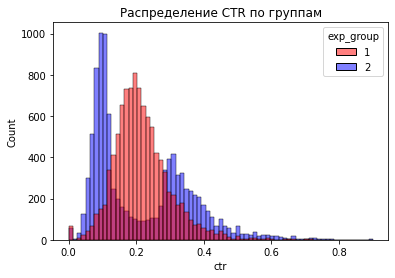

In [19]:
groups = sns.histplot(data = df, 
              x='ctr', 
              hue='exp_group', 
              palette = ['r', 'b'],
              alpha=0.5,
              kde=False)
plt.title("Распределение CTR по группам")
plt.show()

Очень разная форма распределений CTR  по группам. В группе 1 (контрольной) унимодальное распределение, в группе 2 (тестовой) распределение бимодальное. Это говорит о том, что тестируемое изменение работает на разных пользователей противоположным образом. Есть те, кому нововведение понравилось (высокий CTR), и те, кто его не принял (низкий CTR).

## T-тест

Нулевая гипотеза:
     Средние значения CTR в группе 1 (контроль) и группе 2 (тест) равны.  
     
Альтернативная гипотеза:
       Средние значения CTR в группах различаются.

In [20]:
alpha = 0.05

In [21]:
Ttest = stats.ttest_ind(df[df.exp_group == 1].ctr,
                df[df.exp_group == 2].ctr,
                equal_var=False)

In [22]:
Ttest

Ttest_indResult(statistic=0.4051491913112757, pvalue=0.685373331140751)

In [23]:
if Ttest.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Не получилось отвергнуть нулевую гипотезу


T-тест не нашел различий в средних значений CTR между группами.
Проблема в том, что среднее значение для бимодального распределения тестовой группы - некорректная метрика.  Среднее 0.216 попадает в провал между двумя пиками распределения и мало что характеризует.

## Тест Манна-Уитни:

Нулевая гипотеза: Распределение значений CTR в контрольной группе и в тестовой группе одинаковы.


Альтернативная гипотеза: Распределение значений CTR в контрольной группе и в тестовой группе различаются.

In [24]:
mannwhitneyu = stats.mannwhitneyu(df[df.exp_group == 1].ctr, 
                   df[df.exp_group == 2].ctr,
                   alternative = 'two-sided')
mannwhitneyu

MannwhitneyuResult(statistic=55189913.0, pvalue=4.632205841806026e-45)

In [25]:
if mannwhitneyu.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Отвергаем нулевую гипотезу


Тест Манна-Уитни отвергает нулевую гипотезу, значит распределения CTR в группах статистически значимо различаются. На гистограмме распределений это четко видно.

## t-тест и тест Манна-Уитни на сглаженном ctr

In [26]:
def get_smothed_ctr(user_likes, user_views, global_ctr, alpha):
    smothed_ctr = (user_likes + alpha * global_ctr) / (user_views + alpha)
    return smothed_ctr

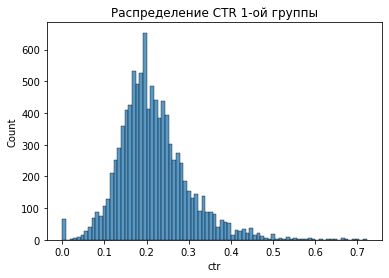

In [27]:
global_ctr_1 = df[df.exp_group == 1].likes.sum()/df[df.exp_group == 1].views.sum()
global_ctr_2 = df[df.exp_group == 2].likes.sum()/df[df.exp_group == 2].views.sum()

group1 = df[df.exp_group == 1].copy()
sns.histplot(group1.ctr, 
             kde = False)
plt.title("Распределение CTR 1-ой группы")
plt.show()

In [28]:
group1['smothed_ctr'] = df.apply(
    lambda x: get_smothed_ctr(x['likes'], x['views'], global_ctr_1, 5), axis=1)

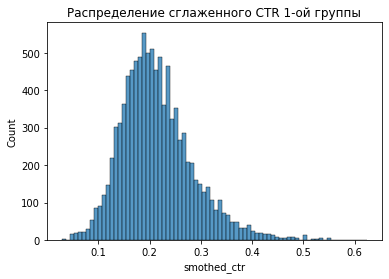

In [29]:
sns.histplot(group1.smothed_ctr, 
             kde = False)
plt.title("Распределение сглаженного CTR 1-ой группы")
plt.show()

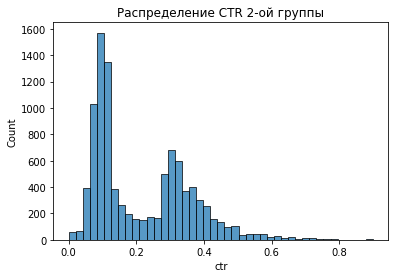

In [30]:
group2 = df[df.exp_group == 2].copy()
sns.histplot(group2.ctr, 
             kde = False)
plt.title("Распределение CTR 2-ой группы")
plt.show()

In [31]:
group2['smothed_ctr'] = df.apply(
    lambda x: get_smothed_ctr(x['likes'], x['views'], global_ctr_2, 5), axis=1)

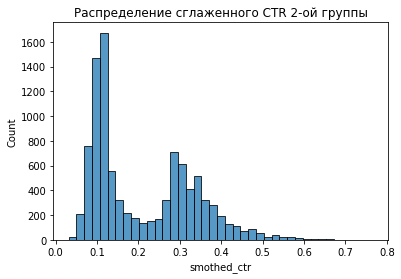

In [32]:
sns.histplot(group2.smothed_ctr, 
             kde = False)
plt.title("Распределение сглаженного CTR 2-ой группы")
plt.show()

In [33]:
Ttest = stats.ttest_ind(group1.smothed_ctr,
                group2.smothed_ctr,
                equal_var=False)
Ttest

Ttest_indResult(statistic=1.9460491517027683, pvalue=0.05166679015318526)

In [34]:
if Ttest.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Не получилось отвергнуть нулевую гипотезу


In [35]:
mannwhitneyu = stats.mannwhitneyu(group1.smothed_ctr,
                group2.smothed_ctr,
                alternative = 'two-sided')
mannwhitneyu

MannwhitneyuResult(statistic=55528353.0, pvalue=2.396534039374286e-50)

In [36]:
if mannwhitneyu.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Отвергаем нулевую гипотезу


Сглаживание убирает шум от пользователей с малым числом просмотров и при t тесте подтягивает p-value к порогу, но не устраняет корневую проблему — бимодальность группы Тест оказался на грани значимости (p = 0,0517)  

Тест Манна-Уитни на сглаженном CTR подтверждает и усиливает вывод с сырых данных: распределения CTR в группах различаются. Сглаживание не меняет качественного вывода, но делает его статистически ещё более уверенным.

## Пуассоновский бутстреп

In [37]:
def bootstrap(likes1, views1, likes2, views2, n_bootstrap=2000):

    poisson_bootstraps1 = stats.poisson(1).rvs(
        (n_bootstrap, len(likes1))).astype(np.int64)

    poisson_bootstraps2 = stats.poisson(1).rvs(
            (n_bootstrap, len(likes2))).astype(np.int64)
    
    globalCTR1 = (poisson_bootstraps1*likes1).sum(axis=1)/(poisson_bootstraps1*views1).sum(axis=1)
    
    globalCTR2 = (poisson_bootstraps2*likes2).sum(axis=1)/(poisson_bootstraps2*views2).sum(axis=1)

    return globalCTR1, globalCTR2

In [38]:
likes1 = df[df.exp_group == 1].likes.to_numpy()
views1 = df[df.exp_group == 1].views.to_numpy()
likes2 = df[df.exp_group == 2].likes.to_numpy()
views2 = df[df.exp_group == 2].views.to_numpy()

In [39]:
ctr1, ctr2 = bootstrap(likes1, views1, likes2, views2)

In [40]:
Ttest = stats.ttest_ind(ctr1,
                ctr2,
                equal_var=False)
Ttest 

Ttest_indResult(statistic=269.6607300688266, pvalue=0.0)

Распределение глобальных CTR для тестовой и контрольной групп.

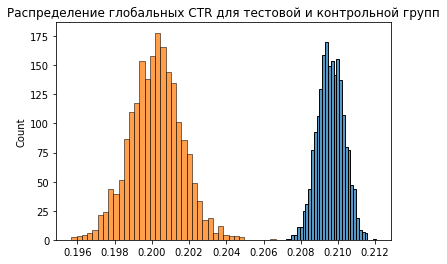

In [41]:
sns.histplot(ctr1)
sns.histplot(ctr2)
plt.title("Распределение глобальных CTR для тестовой и контрольной групп")
plt.show()

Распределение разницы мeжду глобальными CTR.


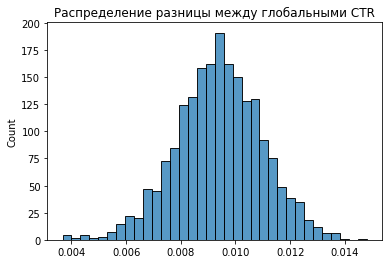

In [42]:
sns.histplot(ctr1 - ctr2)
plt.title("Распределение разницы мeжду глобальными CTR")
plt.show()

Поскольку все значения распределения ctr1 − ctr2 находится выше нуля, то можно сделать вывод, что у контрольной группы 1 глобальный CTR выше, чем у тестовой.  Нулевая гипотеза о равенстве глобальных CTR отвергается.  

## t-тест и тест Манна-Уитни поверх бакетного преобразования.

In [43]:
q1 = """

SELECT exp_group, bucket,
    sum(likes)/sum(views) as bucket_ctr
FROM (SELECT exp_group, 
        xxHash64(user_id)%50 as bucket,
        user_id,
        sum(action = 'like') as likes,
        sum(action = 'view') as views,
        likes/views as ctr
    FROM simulator_20260920.feed_actions 
    WHERE toDate(time) >= '2026-08-28' and toDate(time) <= '2026-09-03' and (exp_group = 2 or exp_group = 1)
    GROUP BY exp_group, bucket, user_id)
GROUP BY exp_group, bucket
"""


In [44]:
df_b = ph.read_clickhouse(q1, connection=connection)

In [45]:
mannwhitneyu = stats.mannwhitneyu(df_b[df_b.exp_group == 1].bucket_ctr, 
                   df_b[df_b.exp_group == 2].bucket_ctr, 
                   alternative = 'two-sided')

In [46]:
if mannwhitneyu.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Отвергаем нулевую гипотезу


In [47]:
ttest = stats.ttest_ind(df_b[df_b.exp_group == 1].bucket_ctr, 
                   df_b[df_b.exp_group == 2].bucket_ctr, 
                   equal_var = False)

In [48]:
if ttest.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Отвергаем нулевую гипотезу


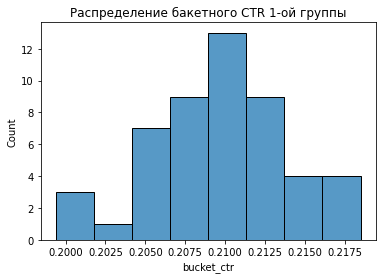

In [49]:
sns.histplot(df_b[df_b.exp_group == 1].bucket_ctr)
plt.title("Распределение бакетного CTR 1-ой группы")
plt.show()

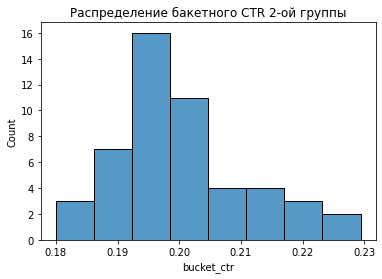

In [50]:
sns.histplot(df_b[df_b.exp_group == 2].bucket_ctr)
plt.title("Распределение бакетного CTR 2-ой группы")
plt.show()

При проведении t теста и теста Манна-Уитни поверх бакетного преобразования получилось отвергнуть нулевую гипотезу о равенстве средних бакетных CTR и равенстве распределений бакетных CTR.  Исходя из гистограмм распределения бакетных CTR и полученных результатов тестов, можно сделать вывод, что CTR в тестовой группе ниже контрольной.

## Вывод:

Был проведен анализ результатов А/В эксперимента, который проходил с 2026-08-28 по 2026-09-03 включительно. Для эксперимента были задействованы 2 и 1 группы. В группе 2 был использован один из новых алгоритмов рекомендации постов, группа 1 использовалась в качестве контроля. 
Первоначально были построены гистограммы  распределений CTR по группам. В группе 1 (контрольной)  унимодальное распределение, в группе 2 (тестовой) распределение бимодальное. Это говорит о том, что тестируемое изменение работает на разных пользователей противоположным образом.

Далее были проведены T-тест и Тест Манна-Уитни на сырых данных. T-тест не нашел различий в средних значений CTR между группами. По тесту Манна-Уитни получилось отвергнуть нулевую гипотезу о равенстве распределений CTR в группах.  

Были проведены t-тест и тест Манна-Уитни на сглаженном ctr. Результаты схожи с результатами тестов на сырых данных.

Пуассоновский бутстреп, а также t-тест и тест Манна-Уитни поверх бакетного преобразования показали, что контрольная группа (группа 1) статистически значимо превосходит тестовую (группу 2) по глобальному CTR.

# Рекомендации:

1. Не раскатывать тест на всех пользователей.  Эффект нового алгоритма отрицательный.
2. Необходимо выяснить причины получения бимодального распределения в тестовой группе. Разбить пользователей группы 2 на два кластера по пикам CTR и понять, чем они отличаются: страна, город, источник трафика, os, возраст.
3. Рассмотреть возможность раскатки только на сегмент пользователей из тестовой группы с высоким пиком СTR.